# SIFT descriptor

About 15 minutes. Build the 128-number SIFT descriptor of an image patch, then use it to match keypoints between two photos.


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tavisualcomputing/viscomp2026/blob/main/Exercises/W5/W5_sift_exercise.ipynb)

## Before you start

Run the setup cell first. It uses the photos next to this notebook, and downloads the ones it needs from the course repository when they are missing (this is what happens in Colab). If the download fails, upload the `.jpg` files from `Exercises/W5` into the Colab file browser.


In [1]:
%matplotlib inline
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

plt.rcParams["figure.dpi"] = 80


IMAGE_BASE_URL = "https://raw.githubusercontent.com/tavisualcomputing/viscomp2026/main/Exercises/W5"


def find_image_dir():
    """Folder with the photos: next to the notebook, in images/, or in Exercises/W5."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        for folder in (cand, cand / "images", cand / "Exercises" / "W5"):
            if (folder / "line.jpg").is_file():
                return folder
    return start


IMAGE_DIR = find_image_dir()


def load_rgb(name):
    """Load a course photo. Downloads it on first use when it is not on disk."""
    path = IMAGE_DIR / name
    if not path.is_file():
        urllib.request.urlretrieve(f"{IMAGE_BASE_URL}/{name}", path)
    return np.asarray(Image.open(path).convert("RGB"))


def downscale(rgb, long_side=960):
    """Shrink so the long side is `long_side`. The JPEG on disk stays full HD."""
    image = Image.fromarray(rgb)
    image.thumbnail((long_side, long_side), Image.Resampling.LANCZOS)
    return np.asarray(image)


def rgb_to_gray(rgb):
    image = rgb.astype(np.float64)
    return (0.2989 * image[:, :, 0] + 0.5870 * image[:, :, 1] + 0.1140 * image[:, :, 2]) / 255.0


def image_gradients(gray):
    """Sobel derivatives. Ix is horizontal, Iy is vertical."""
    Ix = ndimage.sobel(gray, axis=1)
    Iy = ndimage.sobel(gray, axis=0)
    return Ix, Iy


## The idea

A detector tells us *where* a keypoint is and how large it is ($x$, $y$, $\sigma$). To find the same point in another photo we also need to describe what it *looks like*. SIFT describes a keypoint with a vector of 128 numbers:

1. Cut a $16 \times 16$ patch around the keypoint (its size follows $\sigma$, so a keypoint of any scale gives a patch of the same size).
2. Measure the **dominant gradient direction** of the patch: the direction in which most of the (strong) edges point. Cut the patch again, turned so that this direction is the new "right". Now a rotated photo gives the same patch.
3. Divide the patch into $4 \times 4$ sub-patches, called cells: 16 cells of $4 \times 4$ pixels.
4. In each cell, compute a histogram of gradient orientations with 8 reference angles, using every pixel in the cell.
5. Put the 16 histograms next to each other: $4 \times 4 \times 8 = 128$ dimensions.

```
patch 16 x 16                 one cell, 4 x 4 pixels          its histogram
+----+----+----+----+         +--+--+--+--+                   8 bins of orientation
|    |    |    |    |         |->|->|^ |->|                   #
+----+----+----+----+         +--+--+--+--+                   # #
|    |    |    |    |         |->|->|->|->|                   # # #
+----+----+----+----+   -->   +--+--+--+--+   -->   ......     # # # . . . . .
|    |    |    |    |         |^ |->|->|->|                   -pi         pi
+----+----+----+----+         +--+--+--+--+
|    |    |    |    |         |->|->|->|->|   each arrow is the gradient direction of one pixel
+----+----+----+----+         +--+--+--+--+
```

(The diagram shows steps 3 to 5.)

Why this works: a histogram records *which directions the edges in the cell point to*, but not exactly where in the cell they sit. A small shift of the patch changes the cell contents only a little.

We add one step that the slide does not list: scale the final vector to length 1. Then a brighter or higher-contrast copy of the same patch gives the same descriptor.


## Tool: gradient magnitude and orientation

At every pixel, the gradient is an arrow with two components: `gx` (change in the horizontal direction) and `gy` (change in the vertical direction). `np.gradient(patch)` returns these two $16 \times 16$ arrays. The histogram needs the arrow as a **length** and a **direction**:

- Length (magnitude): $\sqrt{g_x^2 + g_y^2}$, the Pythagorean theorem. `np.hypot(gx, gy)` computes exactly this for every pixel at once.
- Direction (orientation): `np.arctan2(gy, gx)` gives the angle of the arrow in radians, between $-\pi$ and $\pi$. Angle 0 points right (brighter to the right), $\pi/2$ points down the image.

Example: `gx = 3`, `gy = 4` gives `np.hypot(3, 4) = 5`.

## Tool: cutting a block out of an array (slicing)

`a[row0:row1, col0:col1]` returns the block of `a` from row `row0` up to, but **not including**, row `row1`, and from column `col0` up to, but not including, column `col1`.

```python
a = np.arange(16).reshape(4, 4)
# [[ 0  1  2  3]
#  [ 4  5  6  7]
#  [ 8  9 10 11]
#  [12 13 14 15]]
a[0:2, 2:4]      # rows 0 and 1, columns 2 and 3  ->  [[2 3]
                 #                                      [6 7]]
```

In the descriptor, cell `(cell_i, cell_j)` covers rows `4*cell_i` to `4*cell_i + 4` and columns `4*cell_j` to `4*cell_j + 4`.

## Tool: dominant direction

If the whole photo is rotated by 25 degrees, every gradient orientation in a patch grows by 25 degrees, so the 8 histograms of the descriptor shift and no longer match. The fix: measure one reference direction per patch and describe the patch relative to it. The reference is the fullest bin of an orientation histogram over **all** 256 pixels of the patch. Here we use 36 bins of 10 degrees, which gives an angle precise to about 5 degrees. You already write `orientation_histogram` for the cells, so the same function does this job with `bins=36`. `np.argmax(hist)` gives the index of the largest entry.

The given `describe` below uses your function in two steps: cut an upright patch, measure its dominant direction `theta`, then cut the patch again with its sampling grid turned by `theta`.

## Tool: weighted histogram with `np.histogram`

`np.histogram(values, bins=8, range=(a, b), weights=w)` splits $[a, b)$ into 8 equal bins and returns two arrays. The first array holds, per bin, the sum of the weights of all values that fall inside that bin. Without `weights` it counts how many values fall in each bin. Keep only the first array: `np.histogram(...)[0]`.

```python
values  = np.array([0.1, 0.2, 0.9])      # which bin?
weights = np.array([1.0, 2.0, 5.0])      # how much does each count?
np.histogram(values, bins=2, range=(0, 1), weights=weights)[0]
# bin [0, 0.5): 0.1 and 0.2 land here -> 1 + 2 = 3
# bin [0.5, 1): 0.9 lands here        -> 5
# result: [3., 5.]
```

For the descriptor the values are the gradient **orientations** (angles from `np.arctan2`, in $[-\pi, \pi)$) and the weights are the gradient **magnitudes**. A pixel with a strong edge counts more than a pixel on a flat area.


## Your turn

Three short functions. The check below them should print `Descriptor check passed` before you move on.


In [5]:
def orientation_histogram(mag, ang, bins=8):
    """Histogram of gradient orientations, weighted by magnitude.

    `mag` and `ang` are arrays of the same shape (for example the pixels of
    one cell). The `bins` equal bins cover [-pi, pi). Pixel p adds mag[p] to
    the bin that contains ang[p]. Use `np.histogram` and keep only the counts.
    """
    return np.histogram(ang, bins, (-np.pi, np.pi), False, mag)[0]


In [9]:
def dominant_orientation(patch):
    """Angle (radians) of the strongest gradient direction in a patch.

    Histogram the orientations of ALL pixels of the patch (weighted by
    magnitude) into 36 bins of 10 degrees. Return the angle at the center
    of the fullest bin.
    """
    # GIVEN: gradient magnitude and orientation of every pixel.
    gy, gx = np.gradient(patch)
    mag = np.hypot(gx, gy)
    ang = np.arctan2(gy, gx)

    # Your code here:
    # 1. hist = your orientation_histogram on the whole patch, with bins=36.
    # 2. best = index of the largest entry of hist (np.argmax).
    # 3. Bin k covers [-pi + k*w, -pi + (k+1)*w) with w = 2*pi/36.
    #    Return the angle in the middle of bin `best`.
    hist = orientation_histogram(mag, ang, 36)
    best = np.argmax(hist)
    w = 2 * np.pi / 36
    direction = (-(2 * np.pi) + 2 * best * w + w) / 2
    return direction


In [20]:
def sift_descriptor(patch):
    """128-D descriptor of a 16 x 16 grayscale patch.

    Split the patch into 4 x 4 cells of 4 x 4 pixels. Each cell gives an
    8-bin orientation histogram. Concatenate the 16 histograms (row by row)
    and scale the vector to length 1.
    """
    # GIVEN: gradient magnitude and orientation of every pixel, 16 x 16 each.
    gy, gx = np.gradient(patch)
    mag = np.hypot(gx, gy)       # length of the gradient arrow: sqrt(gx**2 + gy**2)
    ang = np.arctan2(gy, gx)     # direction of the gradient arrow

    histograms = []              # will hold 16 histograms of 8 numbers each
    for cell_i in range(4):      # cell row 0..3
        for cell_j in range(4):  # cell column 0..3
            # Your code here: the pixels of cell (cell_i, cell_j) are
            # rows row0 to row1 (excluding row1) and columns col0 to col1.
            # Cell (0, 0) is rows 0..4 and columns 0..4, cell (0, 1) is
            # rows 0..4 and columns 4..8, and so on.
            row0, row1 = 4 * cell_i, 4 * (cell_i + 1)   # replace None
            col0, col1 = 4 * cell_j, 4 * (cell_j + 1)   # replace None

            # GIVEN: cut the 4 x 4 block of this cell out of mag and ang.
            mag_cell = mag[row0:row1, col0:col1]
            ang_cell = ang[row0:row1, col0:col1]

            # Your code here: histogram of this cell (8 numbers), then add
            # it to the list `histograms`.
            bins = orientation_histogram(mag_cell, ang_cell, 8)
            histograms.append(bins)
            

    # Your code here: join the 16 histograms into one vector of 128 numbers
    # (np.concatenate), divide it by its length (np.linalg.norm), return it.
    vec = np.concatenate(histograms)
    vec_norm = np.linalg.norm(vec)
    return vec / vec_norm


## Check your descriptor

Small synthetic tests. A patch whose brightness increases in one direction must put all of its weight in one orientation bin.


In [21]:
# 1. Histogram: three pixels, each strictly inside a bin.
mag = np.array([1.0, 2.0, 3.0])
ang = np.array([0.1, np.pi / 2 + 0.1, -np.pi + 0.1])      # bins 4, 6, 0
hist = orientation_histogram(mag, ang)
assert hist.shape == (8,), "expected 8 bins"
assert np.allclose(hist, [3, 0, 0, 0, 1, 0, 2, 0]), f"wrong histogram: {hist}"

# 2. Dominant orientation of a ramp: the gradient angle, to within one 10-degree bin.
yy, xx = np.mgrid[0:16, 0:16].astype(float)
assert abs(dominant_orientation(2.0 * xx + yy) - np.arctan2(1, 2)) < np.deg2rad(5.1)
assert abs(dominant_orientation(-xx + 2.0 * yy) - np.arctan2(2, -1)) < np.deg2rad(5.1)

# 3. Descriptor of a ramp. The gradient points the same way at every pixel,
# so every cell has all of its weight in one bin.
ramp = 2.0 * xx + yy                                        # angle = atan(0.5), bin 4
desc = sift_descriptor(ramp)
assert desc.shape == (128,), "expected 4 x 4 x 8 = 128 numbers"
assert abs(np.linalg.norm(desc) - 1.0) < 1e-6, "descriptor must have length 1"
cells = desc.reshape(4, 4, 8)
assert (cells.argmax(axis=2) == 4).all() and np.allclose(np.delete(cells, 4, axis=2), 0)

# 4. A different gradient direction fills a different bin, and a brighter
# copy of the same patch gives the same descriptor.
other = -xx + 2.0 * yy                                      # angle about 2.03, bin 6
assert (sift_descriptor(other).reshape(4, 4, 8).argmax(axis=2) == 6).all()
assert np.allclose(sift_descriptor(3.0 * ramp + 5.0), desc), "brightness and contrast must not matter"
print("Descriptor check passed.")


Descriptor check passed.


## Keypoints and patches (given)

Keypoints come from the blob detector of the previous exercise (bright and dark blobs of the LoG response, with their $\sigma$). `extract_patch` samples a $16 \times 16$ patch whose spacing grows with $\sigma$, and `describe` calls your `sift_descriptor` on the patch of every keypoint. You do not need to modify these.


In [22]:
def scale_normalized_log(image, sigma):
    """Return sigma**2 * Laplacian(Gaussian_sigma * image)."""
    smoothed = ndimage.gaussian_filter(image, sigma)
    return (sigma ** 2) * ndimage.laplace(smoothed)


def blob_detections(image, sigmas, rel_threshold=0.15, polarity="bright"):
    """Return (x, y, sigma, score) for blobs across `sigmas`.

    Bright blobs are minima of the scale-normalized LoG, so the score
    is minus that response. Dark blobs use the response itself.
    A detection is a local maximum of the score in a 3x3x3 neighborhood
    (image x, image y, and the neighboring scale) and clears
    `rel_threshold` times the best score. The first and last scales are
    dropped, because they have no neighbor on one side.
    """
    if polarity == "bright":
        sign = -1.0
    elif polarity == "dark":
        sign = 1.0
    else:
        raise ValueError("polarity must be 'bright' or 'dark'")

    volume = np.stack(
        [sign * scale_normalized_log(image, float(sigma)) for sigma in sigmas]
    )
    local_max = ndimage.maximum_filter(volume, size=(3, 3, 3))
    mask = volume == local_max
    mask[0] = False
    mask[-1] = False

    peak = float(volume.max())
    if peak <= 0:
        return []
    mask &= volume >= rel_threshold * peak

    scale_ids, ys, xs = np.nonzero(mask)
    blobs = []
    for scale_id, y, x in zip(scale_ids, ys, xs):
        blobs.append(
            (int(x), int(y), float(sigmas[scale_id]), float(volume[scale_id, y, x]))
        )
    return blobs


def red_minus_green(rgb):
    """Channel in which a red apple is a bright blob on green leaves."""
    image = rgb.astype(np.float64) / 255.0
    return image[:, :, 0] - image[:, :, 1]


def drop_border(blobs, shape, margin=8):
    height, width = shape
    return [
        blob for blob in blobs
        if margin <= blob[0] < width - margin and margin <= blob[1] < height - margin
    ]


def suppress_overlaps(blobs, min_separation=0.7):
    """Keep the stronger blob when two circles land on the same object."""
    ordered = sorted(blobs, key=lambda blob: -blob[3])
    kept = []
    for x, y, sigma, score in ordered:
        radius = np.sqrt(2.0) * sigma
        clear = True
        for x2, y2, sigma2, _ in kept:
            radius2 = np.sqrt(2.0) * sigma2
            limit = min_separation * max(radius, radius2)
            if (x - x2) ** 2 + (y - y2) ** 2 < limit ** 2:
                clear = False
                break
        if clear:
            kept.append((x, y, sigma, score))
    return kept


def draw_blobs(ax, blobs, color="crimson"):
    for x, y, sigma, _score in blobs:
        circle = plt.Circle(
            (x, y), np.sqrt(2.0) * sigma, fill=False, color=color, linewidth=0.9
        )
        ax.add_patch(circle)


def find_keypoints(gray, max_points=300):
    """Keypoints (x, y, sigma, score): the strongest bright and dark LoG blobs."""
    sigmas = np.geomspace(2.0, 12.0, 8)
    points = blob_detections(gray, sigmas, rel_threshold=0.1, polarity="bright")
    points += blob_detections(gray, sigmas, rel_threshold=0.1, polarity="dark")
    points = suppress_overlaps(drop_border(points, gray.shape, margin=20))
    return sorted(points, key=lambda point: -point[3])[:max_points]


def extract_patch(smoothed, x, y, sigma, theta=0.0):
    """16 x 16 patch around (x, y). The sample spacing is 0.75 * sigma pixels,
    so a keypoint twice as large covers twice as many pixels: the patch shows
    the same content whatever the scale. The patch grid is turned by the angle
    `theta` (radians), so theta = 0 is an upright patch."""
    steps = (np.arange(16) - 7.5) * (0.75 * sigma)
    u, v = np.meshgrid(steps, steps)
    px = x + u * np.cos(theta) - v * np.sin(theta)
    py = y + u * np.sin(theta) + v * np.cos(theta)
    return ndimage.map_coordinates(smoothed, [py, px], order=1, mode="nearest")


def describe(gray, keypoints):
    """One 128-D descriptor per keypoint, using your dominant_orientation and
    sift_descriptor: measure the dominant direction on an upright patch, then
    cut the patch again turned to that direction and describe it."""
    smoothed = {}
    descriptors = []
    for x, y, sigma, _score in keypoints:
        if sigma not in smoothed:
            smoothed[sigma] = ndimage.gaussian_filter(gray, sigma)
        upright = extract_patch(smoothed[sigma], x, y, sigma)
        theta = dominant_orientation(upright)
        turned = extract_patch(smoothed[sigma], x, y, sigma, theta)
        descriptors.append(sift_descriptor(turned))
    return np.array(descriptors)


`images/SIFTa.jpg` and `images/SIFTb.jpg` show the same facade from two places. Both are shrunk to 1280 pixels on the long side. The green circles are the 300 strongest keypoints, with radius $\sigma\sqrt{2}$.


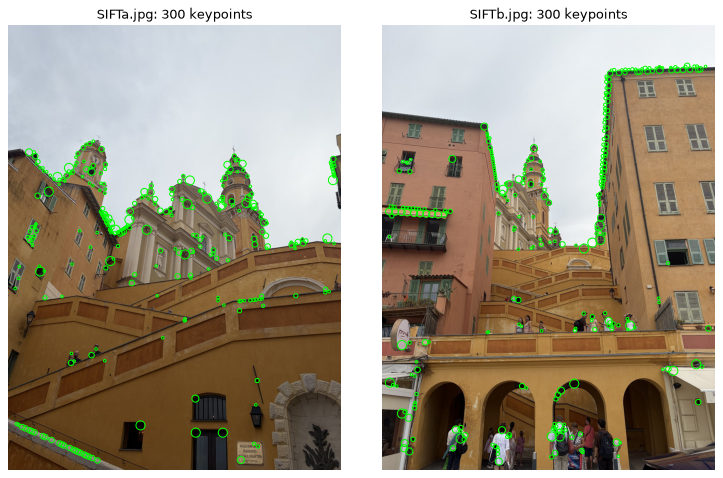

In [23]:
views = {}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 6))
for ax, name in zip(axes, ("SIFTa.jpg", "SIFTb.jpg")):
    rgb = downscale(load_rgb(name), long_side=1280)
    keypoints = find_keypoints(rgb_to_gray(rgb))
    views[name] = (rgb, keypoints)
    ax.imshow(rgb)
    draw_blobs(ax, keypoints, color="lime")
    ax.set_title(f"{name}: {len(keypoints)} keypoints")
    ax.set_axis_off()
fig.tight_layout()
plt.show()


## One descriptor

Left: a keypoint. Middle: the $16 \times 16$ patch with the $4 \times 4$ cells. Right: your 128 numbers, one row per cell and one column per orientation bin. A bright entry means many strong edges of that direction inside that cell.


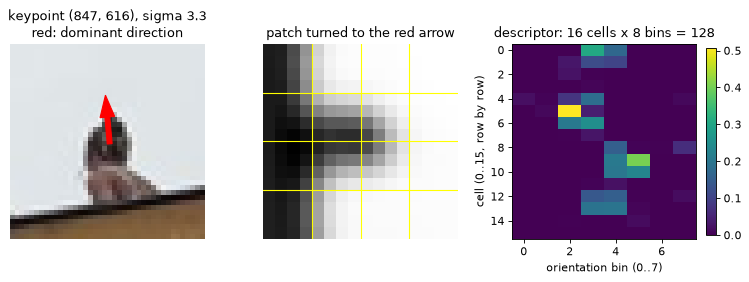

In [24]:
# One keypoint, its 16 x 16 patch, and its 128 numbers.
rgb_a, kp_a = views["SIFTa.jpg"]
gray_a = rgb_to_gray(rgb_a)
x, y, sigma, _ = kp_a[0]
smoothed = ndimage.gaussian_filter(gray_a, sigma)
theta = dominant_orientation(extract_patch(smoothed, x, y, sigma))
patch = extract_patch(smoothed, x, y, sigma, theta)
descriptor = sift_descriptor(patch)

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.4))
half = int(6 * sigma)
left, top = max(int(x) - half, 0), max(int(y) - half, 0)
axes[0].imshow(rgb_a[top:int(y) + half, left:int(x) + half])
axes[0].arrow(x - left, y - top, 3 * sigma * np.cos(theta), 3 * sigma * np.sin(theta),
              color="red", width=0.3 * sigma, length_includes_head=True)
axes[0].set_title(f"keypoint ({x}, {y}), sigma {sigma:.1f}\nred: dominant direction")

axes[1].imshow(patch, cmap="gray")
for edge in (3.5, 7.5, 11.5):
    axes[1].axhline(edge, color="yellow", linewidth=1)
    axes[1].axvline(edge, color="yellow", linewidth=1)
axes[1].set_title("patch turned to the red arrow")

image = axes[2].imshow(descriptor.reshape(16, 8), cmap="viridis", aspect="auto")
axes[2].set_xlabel("orientation bin (0..7)")
axes[2].set_ylabel("cell (0..15, row by row)")
axes[2].set_title("descriptor: 16 cells x 8 bins = 128")
fig.colorbar(image, ax=axes[2], fraction=0.046)
for ax in axes[:2]:
    ax.set_axis_off()
fig.tight_layout()
plt.show()


## Matching (given)

To find a keypoint of photo A in photo B, compare its descriptor with all descriptors of B using the Euclidean distance. The closest one is the candidate. Repeated structure (many similar windows) fools this, so we keep a match only if the closest descriptor is clearly closer than the second closest, here $d_1 / d_2 < 0.8$. This is called the ratio test.


In [25]:
def match_descriptors(desc_a, desc_b, ratio=0.8):
    """Lowe's ratio test. Returns a list of (i, j, r).

    Row i of desc_a matches row j of desc_b when the nearest neighbor in
    desc_b is closer than `ratio` times the second nearest. r is that
    distance ratio (smaller means more distinctive).
    """
    sq_a = (desc_a ** 2).sum(axis=1)[:, None]
    sq_b = (desc_b ** 2).sum(axis=1)[None, :]
    dist = np.sqrt(np.maximum(sq_a + sq_b - 2.0 * desc_a @ desc_b.T, 0.0))
    nearest_two = np.argsort(dist, axis=1)[:, :2]
    matches = []
    for i, (j1, j2) in enumerate(nearest_two):
        r = dist[i, j1] / max(dist[i, j2], 1e-12)
        if r < ratio:
            matches.append((i, int(j1), float(r)))
    return matches


def similarity_warp(rgb, angle_deg, scale):
    """Rotate by angle_deg and scale about the center. Returns (warped, forward).

    forward(x, y) gives where the point (x, y) of `rgb` lands in `warped`, so we
    know the true correspondence.
    """
    height, width = rgb.shape[:2]
    center = np.array([(width - 1) / 2, (height - 1) / 2])
    t = np.deg2rad(angle_deg)
    R = scale * np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    yy, xx = np.mgrid[0:height, 0:width]
    src = (np.stack([xx, yy], -1) - center) @ np.linalg.inv(R).T + center
    channels = [
        ndimage.map_coordinates(rgb[:, :, c].astype(float), [src[..., 1], src[..., 0]],
                                order=1, mode="constant", cval=128.0)
        for c in range(3)
    ]
    warped = np.clip(np.stack(channels, axis=-1), 0, 255).astype(np.uint8)
    return warped, lambda x, y: tuple(R @ (np.array([x, y]) - center) + center)


def count_correct(matches, kp_a, kp_b, forward, tol=4.0):
    """How many matches land within `tol` pixels of the known correspondence."""
    good = 0
    for i, j, _r in matches:
        px, py = forward(kp_a[i][0], kp_a[i][1])
        good += np.hypot(px - kp_b[j][0], py - kp_b[j][1]) < tol
    return int(good)


def draw_matches(rgb_a, rgb_b, kp_a, kp_b, matches, limit=60):
    """Side-by-side photos with a line per match, most distinctive first."""
    canvas = np.concatenate([rgb_a, rgb_b], axis=1)
    fig, ax = plt.subplots(figsize=(9.5, 6.5))
    ax.imshow(canvas)
    offset = rgb_a.shape[1]
    for i, j, _r in sorted(matches, key=lambda m: m[2])[:limit]:
        ax.plot([kp_a[i][0], kp_b[j][0] + offset], [kp_a[i][1], kp_b[j][1]], linewidth=0.8)
    ax.set_axis_off()
    fig.tight_layout()
    return ax


## Test 1: A against a shrunk copy of A

We know where every point of A lands in the copy, so we can count the correct matches. The lines join the 40 most distinctive matches.


143 matches, 126 correct (88%)


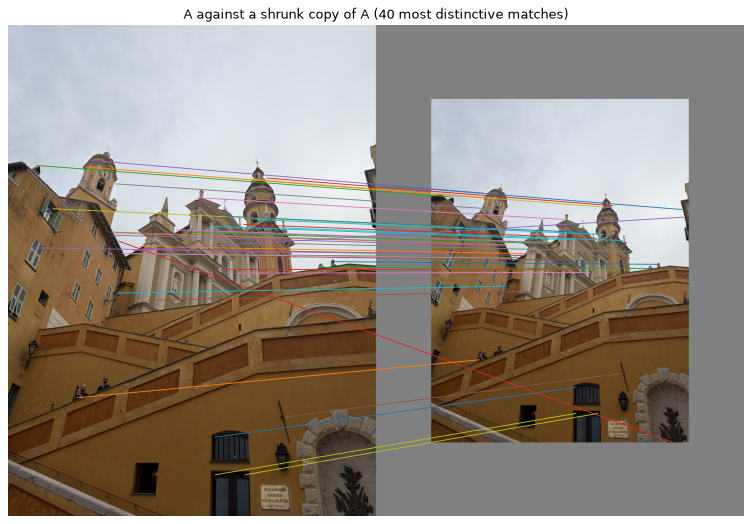

In [26]:
# Photo A against a copy shrunk to 70%. The true correspondence is known.
desc_a = describe(gray_a, kp_a)
rgb_s, forward = similarity_warp(rgb_a, angle_deg=0, scale=0.7)
gray_s = rgb_to_gray(rgb_s)
kp_s = find_keypoints(gray_s)
desc_s = describe(gray_s, kp_s)

matches = match_descriptors(desc_a, desc_s, ratio=0.8)
good = count_correct(matches, kp_a, kp_s, forward)
print(f"{len(matches)} matches, {good} correct ({100 * good / max(len(matches), 1):.0f}%)")

draw_matches(rgb_a, rgb_s, kp_a, kp_s, matches, limit=40)
plt.title("A against a shrunk copy of A (40 most distinctive matches)")
plt.show()


## Test 2: A against a rotated copy of A

Same test, but the copy is rotated by 25 degrees instead of shrunk. This only works because of your `dominant_orientation`.


99 matches, 68 correct (69%)


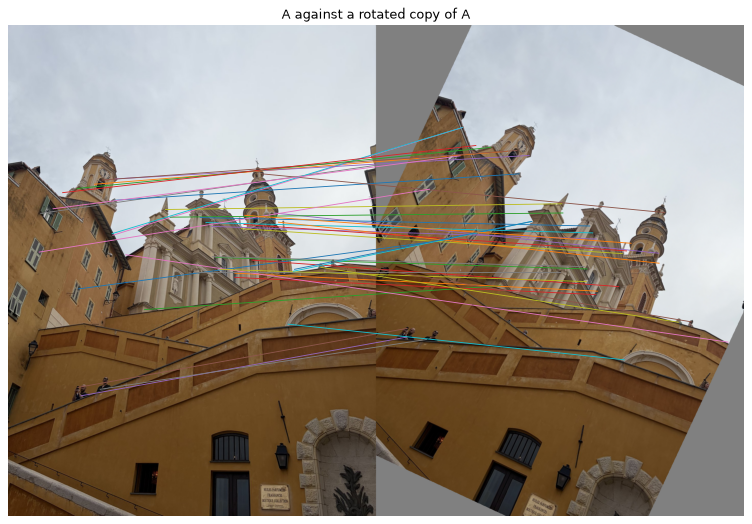

In [27]:
# The same test with a copy rotated by 25 degrees.
rgb_r, forward = similarity_warp(rgb_a, angle_deg=25, scale=1.0)
gray_r = rgb_to_gray(rgb_r)
kp_r = find_keypoints(gray_r)
desc_r = describe(gray_r, kp_r)

matches = match_descriptors(desc_a, desc_r, ratio=0.8)
good = count_correct(matches, kp_a, kp_r, forward)
print(f"{len(matches)} matches, {good} correct ({100 * good / max(len(matches), 1):.0f}%)")

draw_matches(rgb_a, rgb_r, kp_a, kp_r, matches, limit=40)
plt.title("A against a rotated copy of A")
plt.show()


## The two real photos


26 matches between SIFTa and SIFTb


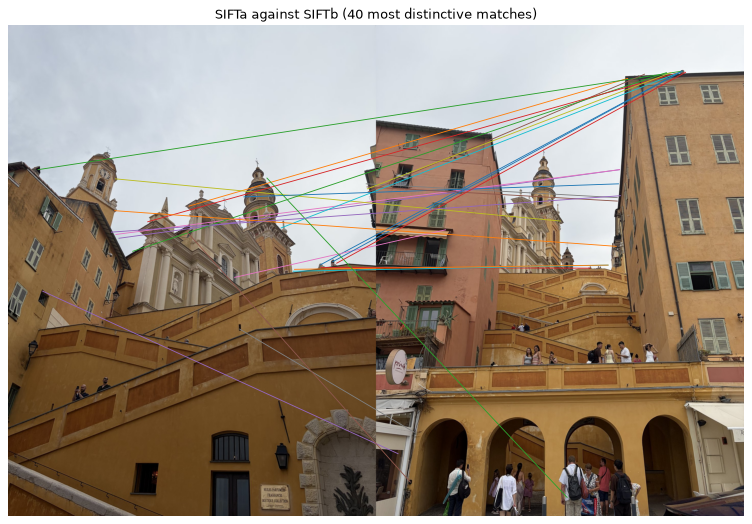

In [28]:
# The two real photos. There is no ground truth, so judge the lines by eye.
rgb_b, kp_b = views["SIFTb.jpg"]
desc_b = describe(rgb_to_gray(rgb_b), kp_b)
matches = match_descriptors(desc_a, desc_b, ratio=0.8)
print(f"{len(matches)} matches between SIFTa and SIFTb")

draw_matches(rgb_a, rgb_b, kp_a, kp_b, matches, limit=40)
plt.title("SIFTa against SIFTb (40 most distinctive matches)")
plt.show()


## Look at the matches

1. Test 1: most matches are correct although the copy is much smaller. Which part of the pipeline above makes the descriptor ignore the scale?
2. Test 2: most matches are correct although the copy is rotated. In `describe`, change `theta` to `0.0` before cutting `turned` (so the patch is never turned) and rerun Test 2. What happens to the number of correct matches? Explain it with what a rotation does to the gradient orientations.
3. Brightness: why can we scale the descriptor to length 1 without losing information about the shape of the patch?
4. In the real pair, most matches are wrong. Name two reasons (think about viewpoint change and repeated windows).
5. Change `ratio` to 0.9 and then 0.6 in Test 1. How do the number of matches and the percentage of correct ones change?
